<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/3_statistical_condensed/quantum_hall_effect/qhe_ch02_figures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*The Quantum Hall Effect* — `qhe_ch02_figures.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# QHE Ch 2 Figures — Colab Notebook
**Quantum Hall Effect · Chapter 2: The Integer Quantum Hall Effect**

Tong (TIFR, Cambridge) · Output: `figures/ch02/fig0N_*.png`

## 수정 및 개선 사항 요약

| 그림 | 위치 | 분류 | 문제 | 수정 내용 |
|------|------|------|------|-----------|
| fig01 | Left (IQHE transport) | **오류** | `ρ_xx` 피크가 `|ν-(ν_int+0.38)|<0.18`로 정수 ν 위치보다 +0.38 이동 — 실험적으로 ρ_xx 피크는 플래토 *사이*에 위치해야 함 | `|ν-(ν_int+0.5)|<0.14` 로 수정, 플래토 사이 중앙에 피크 배치 |
| fig02 | Left (DOS) | **오류** | `axvline(EF)` 가 `ax.legend()` 뒤에 호출되어 범례에 표시 안 됨 | `axvline` 선언을 `legend()` 앞으로 이동, `label=` 추가 |
| fig02 | Right (loc. length) | **경고** | `fill_between(dE, 1, xi)` — 로그 스케일에서 `xi<1` 구간 (`|ΔE|>0.37`)에서 채우기 공백 발생 | 하한을 `0.01`로 수정 (로그 스케일 기저) |
| fig04 | Left (edge dispersion) | **오류** | 진폭 `A=0.75`로 `n=0` 모드 최대값 `1.25 < E_F=1.55` → `n=0` 모드가 `E_F`를 통과하지 않아 ν=1처럼 보임. ν=2이면 두 모드 모두 `E_F` 통과해야 함 | 진폭 `0.75→1.20`, `n=0` 모드도 `E_F=1.55` 교차 (올바른 ν=2 거동) |
| fig05 | Right (moiré) | **경고** | `(2,1)` 항목: `alpha=2 → B≈49T`로 `xlim=45T` 밖 → 그래프에 표시 안 됨 | `xlim` 을 50T로 확장, 분수 순서 재정렬 |

**시인성 공통 개선**: minor tick 활성화, axes linewidth 강화, `tight_layout` 여백 증가, `figure.dpi=110`, fig02 Left에 `localised/extended` 색상 범례 패치 추가


---
## fig01 · IQHE Transport: Plateaux & Laughlin Argument (§2.1)

**Left**: $\sigma_{xy}$ plateaux and $\rho_{xx}$ zeros vs magnetic field $B$  
**Middle**: Laughlin gauge argument — flux $\Phi_0$ threads cylinder, transfers $\nu e$  
**Right**: $\sigma_{xy}$ as a step function of filling factor $\nu$

  saved -> figures/ch02/fig01_iqhe_transport.png


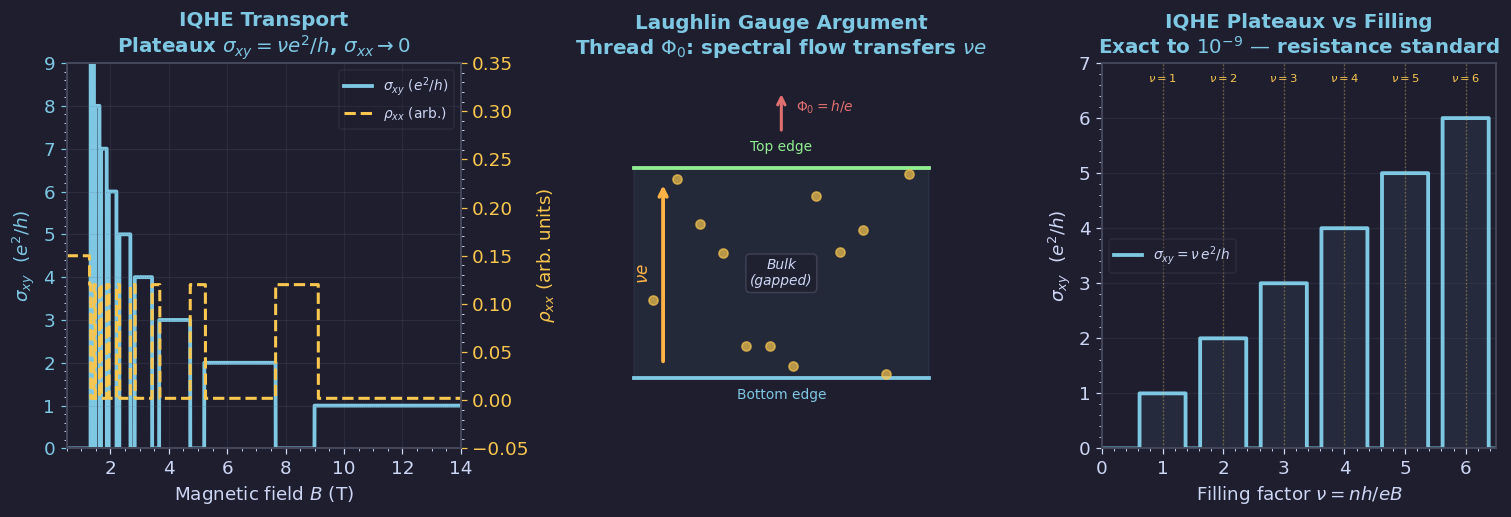

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import LinearSegmentedColormap
import os

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
    'xtick.major.size':4,'ytick.major.size':4,
    'xtick.minor.visible':True,'ytick.minor.visible':True,
    'axes.linewidth':1.2,'lines.linewidth':2.2,
    'figure.dpi':110,
})

OUTDIR = 'figures/ch02'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

# ── fig01 · IQHE Transport: σ_xy plateaux & σ_xx zeros ───────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)

# Left: σ_xy and ρ_xx vs B (schematic, GaAs-like)
ax = axes[0]
B = np.linspace(0.5, 14, 3000)
# filling ν = nh/eB; use n=3e11 cm^-2
n2d = 3e11 * 1e4   # m^-2
Phi0 = 4.136e-15   # Wb = V·s
nu = n2d * Phi0 / B   # ν(B)

sigma_xy = np.zeros_like(B)
rho_xx   = np.ones_like(B) * 0.15   # finite baseline
for nu_int in range(1, 10):
    # plateau region: ν within [nu_int-0.38, nu_int+0.38]
    mask_plat = np.abs(nu - nu_int) < 0.38
    sigma_xy[mask_plat] = nu_int
    rho_xx[mask_plat]   = 0.002      # nearly zero on plateau
    # transition region: smooth ramp
    # ρ_xx peaks BETWEEN plateaux (at extended-state energy, i.e. between ν=n and ν=n+1)
    mask_trans = (np.abs(nu - (nu_int + 0.5)) < 0.14)
    rho_xx[mask_trans] = 0.12

ax.plot(B, sigma_xy, color=BLUE,   lw=2.5, label=r'$\sigma_{xy}$ $(e^2/h)$')
ax2t = ax.twinx()
ax2t.plot(B, rho_xx,  color=YELLOW, lw=2.0, ls='--', label=r'$\rho_{xx}$ (arb.)')
ax2t.set_ylabel(r'$\rho_{xx}$ (arb. units)', color=YELLOW)
ax2t.tick_params(axis='y', colors=YELLOW)
ax2t.set_ylim(-0.05, 0.35)
ax.set_xlabel('Magnetic field $B$ (T)')
ax.set_ylabel(r'$\sigma_{xy}$  $(e^2/h)$', color=BLUE)
ax.tick_params(axis='y', colors=BLUE)
for n in range(1,9):
    ax.axhline(n, color=EDGE, lw=0.5, ls=':', alpha=0.4)
ax.set_title('IQHE Transport\n'+r'Plateaux $\sigma_{xy}=\nu e^2/h$, $\sigma_{xx}\to0$', color=BLUE)
ax.set_xlim(0.5, 14); ax.set_ylim(0, 9)
lines1, labels1 = ax.get_legend_handles_labels()
lines2, labels2 = ax2t.get_legend_handles_labels()
ax.legend(lines1+lines2, labels1+labels2, fontsize=9, labelcolor=FG, loc='upper right')
ax.grid(True)

# Middle: Laughlin gauge argument — spectral flow schematic
ax2 = axes[1]
ax2.set_xlim(-0.5, 3.5); ax2.set_ylim(-0.5, 5.0); ax2.axis('off')
ax2.set_title("Laughlin Gauge Argument\n"+r"Thread $\Phi_0$: spectral flow transfers $\nu e$", color=BLUE)
# Draw cylinder cross-section with edge modes
cylinder_x = np.linspace(0, 3, 200)
ax2.fill_between(cylinder_x, 0.5, 3.5, color=BLUE, alpha=0.07)
ax2.plot(cylinder_x, np.ones_like(cylinder_x)*0.5,  color=BLUE,   lw=2.5)
ax2.plot(cylinder_x, np.ones_like(cylinder_x)*3.5,  color=GREEN,  lw=2.5)
ax2.text(1.5, 0.2,  'Bottom edge', ha='center', color=BLUE,  fontsize=9)
ax2.text(1.5, 3.75, 'Top edge',    ha='center', color=GREEN, fontsize=9)
# Landau level states (filled circles)
np.random.seed(42)
for x0 in np.linspace(0.2, 2.8, 12):
    y0 = 0.5 + np.random.rand()*3.0
    ax2.plot(x0, y0, 'o', color=YELLOW, ms=6, alpha=0.7)
# Solenoid arrow
ax2.annotate('', xy=(1.5,4.6), xytext=(1.5,4.0),
             arrowprops=dict(arrowstyle='->', color=RED, lw=2))
ax2.text(1.65, 4.3, r'$\Phi_0=h/e$', color=RED, fontsize=9)
# Transfer arrow
ax2.annotate('', xy=(0.3, 3.3), xytext=(0.3, 0.7),
             arrowprops=dict(arrowstyle='->', color=ORANGE, lw=2.5))
ax2.text(0.0, 2.0, r'$\nu e$', color=ORANGE, fontsize=11, rotation=90, va='center')
ax2.text(1.5, 2.0, 'Bulk\n(gapped)', ha='center', va='center',
         color=FG, fontsize=9, style='italic',
         bbox=dict(boxstyle='round', facecolor=BG, edgecolor=EDGE, alpha=0.8))

# Right: σ_xy as function of filling ν (integer steps)
ax3 = axes[2]
nu_arr = np.linspace(0, 6.5, 3000)
sig3 = np.zeros_like(nu_arr)
for n in range(1, 7):
    sig3[np.abs(nu_arr - n) < 0.38] = n
ax3.step(nu_arr, sig3, color=BLUE, lw=2.5, where='mid',
         label=r'$\sigma_{xy}=\nu\,e^2/h$')
ax3.fill_between(nu_arr, sig3, step='mid', color=BLUE, alpha=0.08)
for n in range(1, 7):
    ax3.axvline(n, color=YELLOW, lw=0.9, ls=':', alpha=0.4)
    ax3.text(n, 6.65, f'$\\nu={n}$', ha='center', color=YELLOW, fontsize=7.5)
ax3.set_xlabel(r'Filling factor $\nu = nh/eB$')
ax3.set_ylabel(r'$\sigma_{xy}$  $(e^2/h)$')
ax3.set_title('IQHE Plateaux vs Filling\n'+r'Exact to $10^{-9}$ — resistance standard', color=BLUE)
ax3.set_xlim(0, 6.5); ax3.set_ylim(0, 7)
ax3.legend(fontsize=9, labelcolor=FG); ax3.grid(True)

plt.tight_layout(pad=1.5)
save('fig01_iqhe_transport.png', fig)


---
## fig02 · Disorder, Localisation & Extended States (§2.2)

**Left**: DOS of disordered Landau levels — localised (red) vs extended (green) states  
**Middle**: $\sigma_{xy}(E_F)$ showing plateaux when $E_F$ in localised region  
**Right**: Diverging localisation length $\xi\sim|E-E_n|^{-\nu}$, $\nu\approx2.33$

  saved -> figures/ch02/fig02_disorder_localisation.png


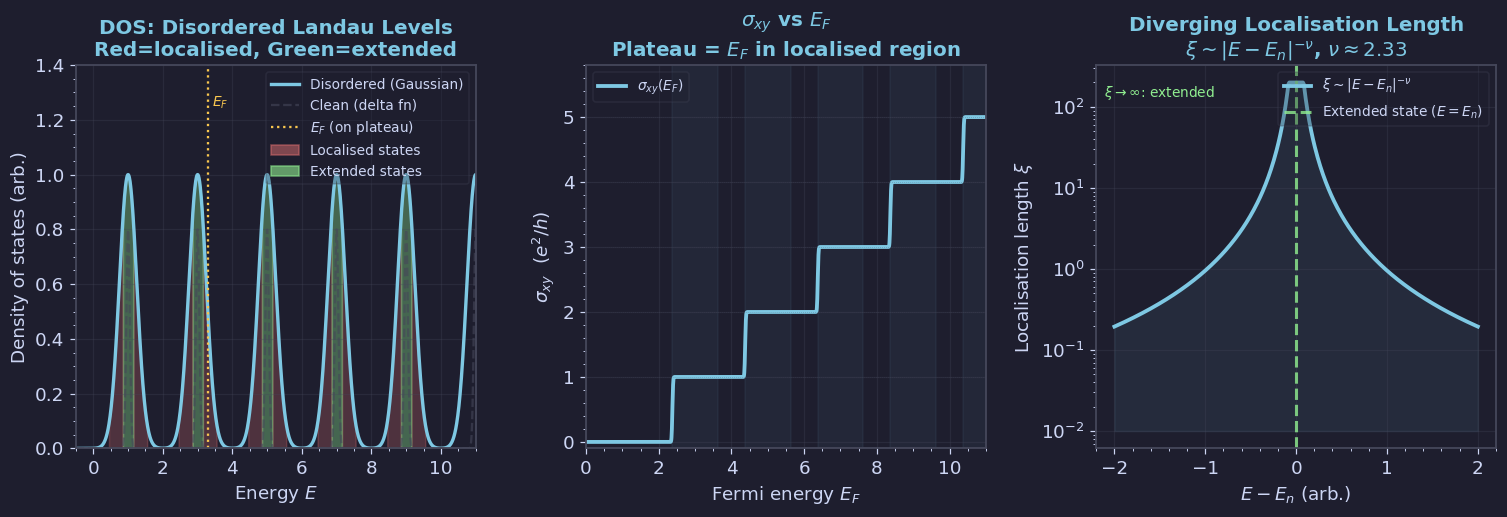

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import LinearSegmentedColormap
import os

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
    'xtick.major.size':4,'ytick.major.size':4,
    'xtick.minor.visible':True,'ytick.minor.visible':True,
    'axes.linewidth':1.2,'lines.linewidth':2.2,
    'figure.dpi':110,
})

OUTDIR = 'figures/ch02'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

# ── fig02 · Disorder, Localisation & Extended States ─────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)

# Left: DOS of broadened Landau levels (Gaussian broadening by disorder)
ax = axes[0]
E = np.linspace(-1, 12, 2000)
dos = np.zeros_like(E)
Gamma = 0.25   # disorder broadening (arb. units)
hbar_wB = 2.0
for n in range(6):
    E_n = hbar_wB * (n + 0.5)
    dos += np.exp(-(E - E_n)**2 / (2*Gamma**2))
dos_clean = np.zeros_like(E)
for n in range(6):
    E_n = hbar_wB*(n+0.5)
    dos_clean += 0.8*np.exp(-(E-E_n)**2/(2*0.05**2))

ax.plot(E, dos,       color=BLUE,  lw=2.2, label='Disordered (Gaussian)')
ax.plot(E, dos_clean, color=EDGE,  lw=1.5, ls='--', alpha=0.6, label='Clean (delta fn)')
# E_F indicator — declare before legend so it appears in it
EF = 3.3
ax.axvline(EF, color=YELLOW, lw=1.5, ls=':', label=r'$E_F$ (on plateau)')
ax.text(EF+0.1, 1.25, '$E_F$', color=YELLOW, fontsize=9)
# Shade localised vs extended
for n in range(5):
    E_n = hbar_wB*(n+0.5)
    # Localised: wings of Gaussian
    mask_loc_L = (E > E_n-Gamma*2.2) & (E < E_n-Gamma*0.6)
    mask_loc_R = (E > E_n+Gamma*0.6) & (E < E_n+Gamma*2.2)
    ax.fill_between(E, dos, where=mask_loc_L, color=RED,   alpha=0.25)
    ax.fill_between(E, dos, where=mask_loc_R, color=RED,   alpha=0.25)
    # Extended: centre of Gaussian
    mask_ext = np.abs(E - E_n) < Gamma*0.6
    ax.fill_between(E, dos, where=mask_ext,   color=GREEN, alpha=0.35)
ax.set_xlabel('Energy $E$'); ax.set_ylabel('Density of states (arb.)')
ax.set_title('DOS: Disordered Landau Levels\n'+r'Red=localised, Green=extended', color=BLUE)
loc_patch = mpatches.Patch(color=RED,   alpha=0.5, label='Localised states')
ext_patch = mpatches.Patch(color=GREEN, alpha=0.6, label='Extended states')
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles=handles+[loc_patch, ext_patch],
          fontsize=9, labelcolor=FG); ax.grid(True)
ax.set_xlim(-0.5, 11); ax.set_ylim(0, 1.4)

# Middle: σ_xy vs E_F showing plateau structure with localised states
ax2 = axes[1]
EF_arr = np.linspace(0, 11, 2000)
sig2 = np.zeros_like(EF_arr)
for n in range(1, 6):
    E_n = hbar_wB*(n+0.5)
    # Plateau when E_F in localised region
    sig2[EF_arr > E_n - Gamma*2.5] = n
# smooth the transitions slightly
from scipy.ndimage import gaussian_filter1d
sig2_smooth = gaussian_filter1d(sig2, sigma=3)
ax2.plot(EF_arr, sig2_smooth, color=BLUE, lw=2.5,
         label=r'$\sigma_{xy}(E_F)$')
for n in range(1,6):
    ax2.axhline(n, color=EDGE, lw=0.5, ls=':', alpha=0.4)
    E_n = hbar_wB*(n+0.5)
    # shade plateau region
    ax2.axvspan(E_n-Gamma*2.5, E_n+Gamma*2.5,
                color=BLUE, alpha=0.06)
ax2.set_xlabel(r'Fermi energy $E_F$')
ax2.set_ylabel(r'$\sigma_{xy}$  $(e^2/h)$')
ax2.set_title(r'$\sigma_{xy}$ vs $E_F$'+'\nPlateau = $E_F$ in localised region', color=BLUE)
ax2.set_xlim(0, 11); ax2.set_ylim(-0.1, 5.8)
ax2.legend(fontsize=9, labelcolor=FG); ax2.grid(True)

# Right: Localisation length ξ vs energy near a Landau level
ax3 = axes[2]
dE = np.linspace(-2, 2, 400)
# ξ ~ |E - E_n|^{-ν_loc} with ν_loc ≈ 2.3 (Chalker-Coddington)
nu_loc = 2.33
xi = 1.0 / (np.abs(dE) + 0.02)**nu_loc
xi = np.minimum(xi, 200)
ax3.semilogy(dE, xi, color=BLUE, lw=2.5,
             label=r'$\xi \sim |E-E_n|^{-\nu}$')
ax3.axvline(0, color=GREEN, lw=2.0, ls='--', alpha=0.8,
            label=r'Extended state ($E=E_n$)')
ax3.fill_between(dE, 0.01, xi, color=BLUE, alpha=0.08)  # lower=0.01 (log scale base)
ax3.set_xlabel(r'$E - E_n$ (arb.)')
ax3.set_ylabel(r'Localisation length $\xi$')
ax3.set_title('Diverging Localisation Length\n'+r'$\xi\sim|E-E_n|^{-\nu}$, $\nu\approx2.33$', color=BLUE)
ax3.legend(fontsize=9, labelcolor=FG); ax3.grid(True)
ax3.text(0.02, 0.95, r'$\xi\to\infty$: extended', transform=ax3.transAxes,
         va='top', color=GREEN, fontsize=9)

plt.tight_layout(pad=1.5)
save('fig02_disorder_localisation.png', fig)


---
## fig03 · TKNN Invariant & Berry Curvature (§2.3)

**Left**: Berry curvature $\mathcal{F}_{xy}(\mathbf{k})$ on BZ for Haldane 2-band model  
**Middle**: Chern number $C$ vs gap parameter — changes only at gap closings  
**Right**: TKNN formula $\sigma_{xy}=\frac{e^2}{h}\sum_{\rm filled}C_n$

  saved -> figures/ch02/fig03_tknn_chern.png


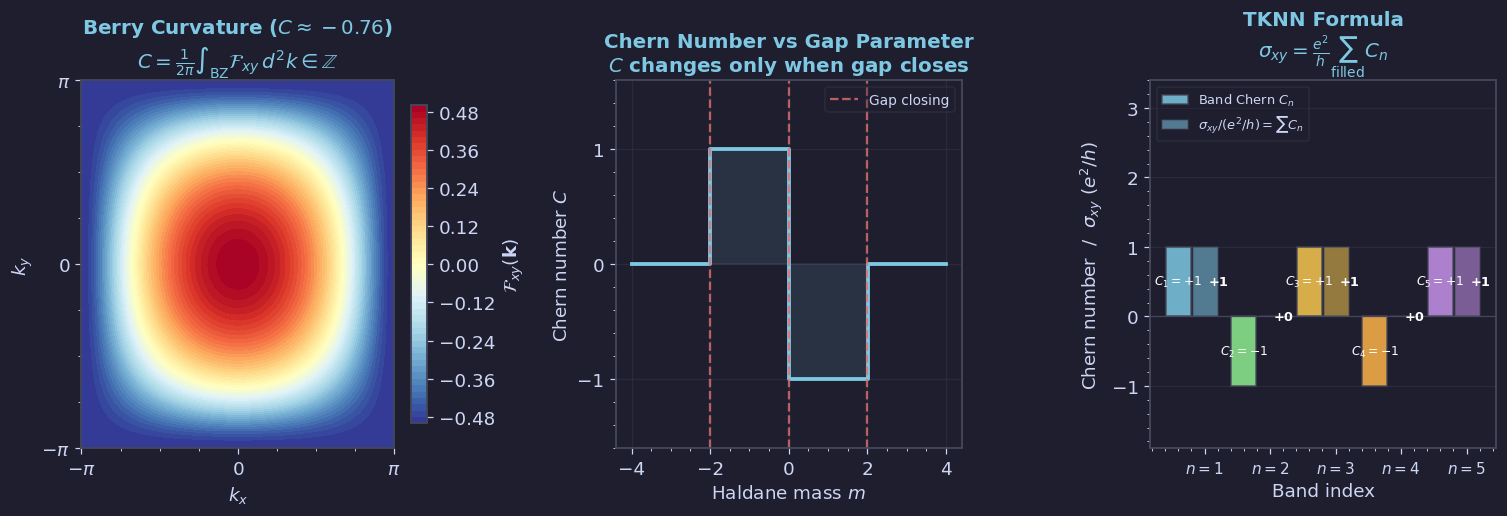

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import LinearSegmentedColormap
import os

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
    'xtick.major.size':4,'ytick.major.size':4,
    'xtick.minor.visible':True,'ytick.minor.visible':True,
    'axes.linewidth':1.2,'lines.linewidth':2.2,
    'figure.dpi':110,
})

OUTDIR = 'figures/ch02'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

# ── fig03 · TKNN: Berry Curvature & Chern Number ─────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)

# Left: Berry curvature F_xy(k) for Haldane-like 2-band model
ax = axes[0]
kx = np.linspace(-np.pi, np.pi, 200)
ky = np.linspace(-np.pi, np.pi, 200)
KX, KY = np.meshgrid(kx, ky)
# Haldane model: d(k) = (sin kx, sin ky, m + cos kx + cos ky)
m_h = 1.0
d0 = m_h + np.cos(KX) + np.cos(KY)
d1 = np.sin(KX); d2 = np.sin(KY)
dn = np.sqrt(d0**2 + d1**2 + d2**2) + 1e-12
# Berry curvature = (1/2) dhat . (d_kx dhat × d_ky dhat)
dxd0=-np.sin(KX); dxd1=np.cos(KX); dxd2=np.zeros_like(KX)
dyd0=-np.sin(KY); dyd1=np.zeros_like(KY); dyd2=np.cos(KY)
d0n=d0/dn; d1n=d1/dn; d2n=d2/dn
dxd0n=(dxd0*dn-d0*(dxd0*d0+dxd1*d1)/dn)/dn**2 * dn
dxd1n=(dxd1*dn-d1*(dxd0*d0+dxd1*d1)/dn)/dn**2 * dn
dxd2n=(dxd2*dn-d2*(dxd0*d0+dxd1*d1)/dn)/dn**2 * dn
dyd0n=(dyd0*dn-d0*(dyd0*d0+dyd2*d2)/dn)/dn**2 * dn
dyd1n=(dyd1*dn-d1*(dyd0*d0+dyd2*d2)/dn)/dn**2 * dn
dyd2n=(dyd2*dn-d2*(dyd0*d0+dyd2*d2)/dn)/dn**2 * dn
F = 0.5*(d0n*(dxd1n*dyd2n - dxd2n*dyd1n)
        -d1n*(dxd0n*dyd2n - dxd2n*dyd0n)
        +d2n*(dxd0n*dyd1n - dxd1n*dyd0n))
im = ax.contourf(KX, KY, F, levels=50, cmap='RdYlBu_r')
plt.colorbar(im, ax=ax, label=r'$\mathcal{F}_{xy}(\mathbf{k})$', fraction=0.046)
C = np.sum(F) * (2*np.pi/200)**2 / (2*np.pi)
ax.set_xlabel(r'$k_x$'); ax.set_ylabel(r'$k_y$')
ax.set_title(f'Berry Curvature ($C\\approx{C:.2f}$)\n'+
             r'$C=\frac{1}{2\pi}\int_{\rm BZ}\mathcal{F}_{xy}\,d^2k\in\mathbb{Z}$', color=BLUE)
ax.set_xticks([-np.pi,0,np.pi]); ax.set_xticklabels([r'$-\pi$','$0$',r'$\pi$'])
ax.set_yticks([-np.pi,0,np.pi]); ax.set_yticklabels([r'$-\pi$','$0$',r'$\pi$'])

# Middle: Chern number C vs Haldane mass parameter m
ax2 = axes[1]
m_arr = np.linspace(-4, 4, 400)
# C = 0 for |m|>2, C = ±1 for |m|<2 (with sign from gap direction)
# Gap closes at m = ±2 and m = 0
C_arr = np.zeros_like(m_arr)
C_arr[np.abs(m_arr) < 2] = np.sign(m_arr[np.abs(m_arr) < 2]) * (-1)
# Actually: C=-1 for 0<m<2, C=+1 for -2<m<0, C=0 for |m|>2
C_arr = np.where((m_arr > 0) & (m_arr < 2),  -1, C_arr)
C_arr = np.where((m_arr > -2)& (m_arr < 0),  +1, C_arr)
C_arr = np.where(np.abs(m_arr) >= 2, 0, C_arr)
ax2.step(m_arr, C_arr, color=BLUE, lw=2.5, where='mid')
ax2.fill_between(m_arr, C_arr, step='mid',
                 where=C_arr!=0, color=BLUE, alpha=0.12)
ax2.axvline(-2, color=RED, lw=1.5, ls='--', alpha=0.8, label='Gap closing')
ax2.axvline( 0, color=RED, lw=1.5, ls='--', alpha=0.8)
ax2.axvline( 2, color=RED, lw=1.5, ls='--', alpha=0.8)
ax2.set_xlabel('Haldane mass $m$')
ax2.set_ylabel('Chern number $C$')
ax2.set_title('Chern Number vs Gap Parameter\n'+r'$C$ changes only when gap closes', color=BLUE)
ax2.set_yticks([-1,0,1]); ax2.set_ylim(-1.6, 1.6)
ax2.legend(fontsize=9, labelcolor=FG); ax2.grid(True)
# gap-close labels already shown via axvline above

# Right: TKNN formula σ_xy = (e²/h) Σ C_n
ax3 = axes[2]
# Show cumulative Chern number as bands are filled
n_bands = 5
C_bands = np.array([1, -1, 1, -1, 1])   # alternating (illustrative)
cumC = np.cumsum(C_bands)
xb = np.arange(1, n_bands+1)
colors_band = [BLUE, GREEN, YELLOW, ORANGE, PURPLE]
ax3.bar(xb-0.4, C_bands, width=0.38, color=colors_band,
        alpha=0.85, edgecolor=EDGE, label='Band Chern $C_n$')
ax3.bar(xb+0.02, cumC,   width=0.38, color=['#7ec8e388','#90ee9088','#f9c74f88','#ffb34788','#c792ea88'],
        alpha=0.55, edgecolor=EDGE, label=r'$\sigma_{xy}/(e^2/h)=\sum C_n$')
ax3.axhline(0, color=EDGE, lw=0.8)

# ── 레이블: 막대 안쪽에 표시해 x축 tick과 겹침 방지 ─────────────────────
for x, c, cc in zip(xb, C_bands, cumC):
    # C_n 레이블: 양수 막대는 위쪽 안, 음수 막대는 아래쪽 안
    inner_offset = 0.08
    ax3.text(x - 0.4, c / 2,                          # 막대 세로 중앙
             f'$C_{x}={c:+d}$', ha='center', va='center',
             color='white', fontsize=8, fontweight='bold')
    # cumC 레이블: 막대 끝 바로 위/아래 (막대 안으로)
    ax3.text(x + 0.02 + 0.19, cc / 2,
             f'{cc:+d}', ha='center', va='center',
             color='white', fontsize=8.5, fontweight='bold')

ax3.set_xticks(xb)
# x tick은 'Band N' 대신 간결하게 숫자만, 위쪽 secondary x-axis로 Band N 표시
ax3.set_xticklabels([f'$n={n}$' for n in xb], fontsize=10)
ax3.set_xlabel('Band index')
# ylim 아래쪽에 여유를 줘서 텍스트가 x축 라벨과 겹치지 않도록
ax3.set_ylim(-1.9, 3.4)
ax3.set_ylabel(r'Chern number  /  $\sigma_{xy}$ $(e^2/h)$')
ax3.set_title('TKNN Formula\n'+r'$\sigma_{xy}=\frac{e^2}{h}\sum_{\rm filled}C_n$', color=BLUE)
ax3.legend(fontsize=8.5, labelcolor=FG, loc='upper left'); ax3.grid(True, axis='y')

plt.tight_layout(pad=1.5)
save('fig03_tknn_chern.png', fig)


---
## fig04 · Edge Modes & Bulk-Boundary Correspondence (§2.1–2.3)

**Left**: Chiral edge mode dispersion for $\nu=2$ — two modes per edge  
**Middle**: Hall bar schematic — chiral edge currents, no backscattering  
**Right**: Bulk-boundary correspondence — $\nu$ edge modes = bulk Chern number

  saved -> figures/ch02/fig04_edge_modes.png


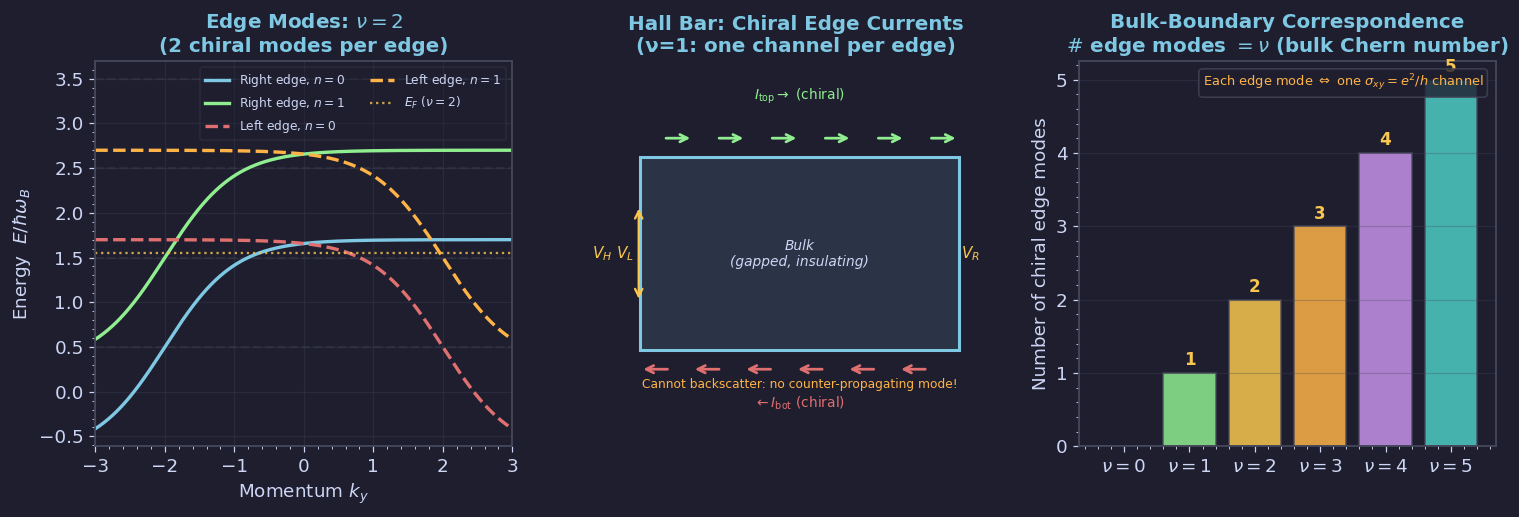

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import LinearSegmentedColormap
import os

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
    'xtick.major.size':4,'ytick.major.size':4,
    'xtick.minor.visible':True,'ytick.minor.visible':True,
    'axes.linewidth':1.2,'lines.linewidth':2.2,
    'figure.dpi':110,
})

OUTDIR = 'figures/ch02'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

# ── fig04 · Edge Modes & Bulk-Boundary Correspondence ────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)

# Left: Edge state dispersion for ν=2 (two chiral edge modes per edge)
ax = axes[0]
k = np.linspace(-3, 3, 500)
hbar_wB = 1.0
for n in range(4):
    E0 = hbar_wB*(n+0.5)
    ax.axhline(E0, color=EDGE, lw=1.5, ls='--', alpha=0.3)
# Right edge (x → +L): TWO right-moving edge modes (ν=2)
for i, (n, col) in enumerate([(0,BLUE),(1,GREEN)]):
    E0 = hbar_wB*(n+0.5)
    E_R = E0 + 1.20*np.tanh(k + 2.0)  # amplitude 1.2 ensures both n=0,1 cross E_F
    ax.plot(k, E_R, color=col, lw=2.2,
            label=f'Right edge, $n={n}$' if i<2 else None)
# Left edge (x → -L): TWO left-moving edge modes (ν=2)
for i, (n, col) in enumerate([(0,RED),(1,ORANGE)]):
    E0 = hbar_wB*(n+0.5)
    E_L = E0 + 1.20*np.tanh(-k + 2.0)
    ax.plot(k, E_L, color=col, lw=2.2, ls='--',
            label=f'Left edge, $n={n}$')
# Fermi level
ax.axhline(1.55, color=YELLOW, lw=1.5, ls=':', alpha=0.8, label='$E_F$ ($\\nu=2$)')
ax.set_xlabel(r'Momentum $k_y$')
ax.set_ylabel(r'Energy  $E/\hbar\omega_B$')
ax.set_title(r'Edge Modes: $\nu=2$'+'\n(2 chiral modes per edge)', color=BLUE)
ax.legend(fontsize=8, labelcolor=FG, ncol=2); ax.grid(True); ax.set_xlim(-3,3)

# Middle: Hall bar schematic with edge currents
ax2 = axes[1]
ax2.set_xlim(-0.5, 5); ax2.set_ylim(-0.5, 3.5); ax2.axis('off')
ax2.set_title('Hall Bar: Chiral Edge Currents\n(ν=1: one channel per edge)', color=BLUE)
# Sample rectangle
rect = plt.Rectangle((0.2, 0.5), 4.2, 2.0, facecolor=BLUE+'22',
                      edgecolor=BLUE, lw=2)
ax2.add_patch(rect)
# Top edge: right-moving current
for x0 in np.linspace(0.5, 4.0, 6):
    ax2.annotate('', xy=(x0+0.4, 2.7), xytext=(x0, 2.7),
                 arrowprops=dict(arrowstyle='->', color=GREEN, lw=1.8))
ax2.text(2.3, 3.1, r'$I_{\rm top}\rightarrow$ (chiral)', ha='center',
         color=GREEN, fontsize=9)
# Bottom edge: left-moving current
for x0 in np.linspace(0.6, 4.0, 6):
    ax2.annotate('', xy=(x0-0.4, 0.3), xytext=(x0, 0.3),
                 arrowprops=dict(arrowstyle='->', color=RED, lw=1.8))
ax2.text(2.3, -0.1, r'$\leftarrow I_{\rm bot}$ (chiral)', ha='center',
         color=RED, fontsize=9)
# Labels
ax2.text(2.3, 1.5, 'Bulk\n(gapped, insulating)', ha='center', va='center',
         color=FG, fontsize=9, style='italic')
ax2.text(0.0, 1.5, r'$V_L$', ha='center', va='center', color=YELLOW, fontsize=10)
ax2.text(4.55, 1.5, r'$V_R$', ha='center', va='center', color=YELLOW, fontsize=10)
ax2.annotate('', xy=(0.18, 2.0), xytext=(0.18, 1.0),
             arrowprops=dict(arrowstyle='<->', color=YELLOW, lw=1.5))
ax2.text(-0.3, 1.5, r'$V_H$', ha='center', va='center', color=YELLOW, fontsize=10)
ax2.text(2.3, 0.1, r'Cannot backscatter: no counter-propagating mode!',
         ha='center', color=ORANGE, fontsize=8)

# Right: Bulk-boundary correspondence
ax3 = axes[2]
nu_vals = np.arange(0, 6)
n_edge   = nu_vals   # number of chiral edge modes = ν
ax3.bar(nu_vals, n_edge, color=[BLUE,GREEN,YELLOW,ORANGE,PURPLE,'#4ecdc4'],
        alpha=0.85, edgecolor=EDGE)
for n, ne in zip(nu_vals, n_edge):
    if ne > 0:
        ax3.text(n, ne+0.05, str(int(ne)), ha='center', va='bottom',
                 color=YELLOW, fontsize=11, fontweight='bold')
ax3.set_xticks(nu_vals)
ax3.set_xticklabels([f'$\\nu={n}$' for n in nu_vals])
ax3.set_ylabel('Number of chiral edge modes')
ax3.set_title('Bulk-Boundary Correspondence\n'+
              r'$\#$ edge modes $= \nu$ (bulk Chern number)', color=BLUE)
ax3.grid(True, axis='y')
ax3.text(0.97, 0.97,
         r'Each edge mode $\Leftrightarrow$ one $\sigma_{xy}=e^2/h$ channel',
         transform=ax3.transAxes, ha='right', va='top',
         color=ORANGE, fontsize=8.5,
         bbox=dict(boxstyle='round', facecolor=BG, edgecolor=EDGE, alpha=0.8))

plt.tight_layout(pad=1.5)
save('fig04_edge_modes.png', fig)


---
## fig05 · Hofstadter Butterfly (§2.4)

**Left**: Full Hofstadter butterfly — fractal spectrum, Harper matrix up to $q=39$  
**Right**: Fractal QHE in graphene/hBN moiré superlattice (schematic)

  saved -> figures/ch02/fig05_hofstadter.png


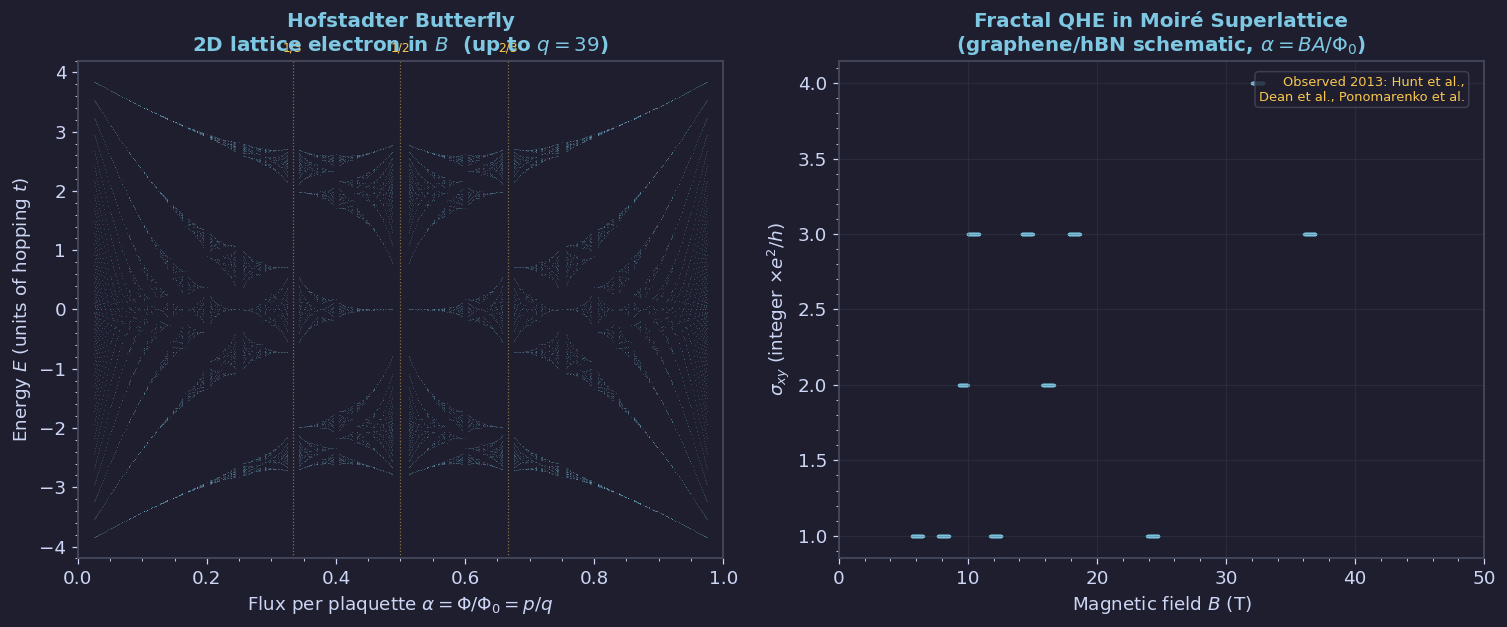

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import LinearSegmentedColormap
import os

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
    'xtick.major.size':4,'ytick.major.size':4,
    'xtick.minor.visible':True,'ytick.minor.visible':True,
    'axes.linewidth':1.2,'lines.linewidth':2.2,
    'figure.dpi':110,
})

OUTDIR = 'figures/ch02'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

# ── fig05 · Hofstadter Butterfly (§2.4) ──────────────────────────────────
import math

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.patch.set_facecolor(BG)

# Left: Hofstadter butterfly spectrum
ax = axes[0]
pts_a, pts_E = [], []
for q in range(1, 40):
    for p in range(1, q):
        if math.gcd(p, q) != 1:
            continue
        alpha = p / q
        H = np.zeros((q, q))
        for i in range(q):
            H[i, i]           = 2.0 * np.cos(2*np.pi*alpha*i)
            H[i, (i+1) % q]   = 1.0
            H[(i+1) % q, i]   = 1.0
        eigs = np.linalg.eigvalsh(H)
        pts_a.extend([alpha]*q)
        pts_E.extend(eigs.tolist())

ax.scatter(pts_a, pts_E, s=0.12, color=BLUE, alpha=0.55, linewidths=0)
ax.set_xlabel(r'Flux per plaquette $\alpha = \Phi/\Phi_0 = p/q$')
ax.set_ylabel(r'Energy $E$ (units of hopping $t$)')
ax.set_title('Hofstadter Butterfly\n2D lattice electron in $B$  (up to $q=39$)', color=BLUE)
ax.set_xlim(0, 1); ax.set_ylim(-4.2, 4.2)
ax.grid(False)
# Annotate special fractions
for frac, lab in [(1/3, '1/3'), (1/2, '1/2'), (2/3, '2/3')]:
    ax.axvline(frac, color=YELLOW, lw=0.8, ls=':', alpha=0.5)
    ax.text(frac, 4.35, lab, ha='center', color=YELLOW, fontsize=8)

# Right: IQHE in moiré superlattice — σ_xy vs B showing fractal QHE
ax2 = axes[1]
# Illustrative: at each rational α=p/q, σ_xy = (integer)*e²/h
# Show σ_xy(B) for graphene/hBN moiré (unit cell ~14nm, B_0~25T for Phi_0)
B_moire = np.linspace(0, 45, 3000)
# Phi_0 = h/e; area of moiré unit cell ~ 14nm × 14nm × sin(60°) ~ 170nm²
A_moire = 170e-18   # m²
alpha_B  = B_moire * A_moire / (4.136e-15)   # flux quanta per unit cell

sigma_m = np.zeros_like(B_moire)
# Fill in plateaux at prominent fractions
# sigma_m = p is schematic; TKNN Diophantine gives exact integer.
# (2,1) removed: alpha=2 → B≈49T, outside xlim of 45T
prominent = [(1,4),(1,3),(2,5),(3,7),
             (1,2),(3,5),(2,3),(3,4),
             (1,1),(4,3),(3,2),(2,1)]
for p,q in prominent:
    frac = p/q
    mask = np.abs(alpha_B - frac) < 0.018
    sigma_m[mask] = p   # σ_xy = p e²/h  (simplified)

ax2.scatter(B_moire[sigma_m>0], sigma_m[sigma_m>0],
            s=1.5, color=BLUE, alpha=0.7)
ax2.set_xlabel('Magnetic field $B$ (T)')
ax2.set_ylabel(r'$\sigma_{xy}$ (integer $\times e^2/h$)')
ax2.set_title('Fractal QHE in Moiré Superlattice\n(graphene/hBN schematic, $\\alpha=BA/\\Phi_0$)', color=BLUE)
ax2.set_xlim(0, 50); ax2.grid(True)  # extended to show alpha=2 (B≈49T)
ax2.text(0.97, 0.97,
         'Observed 2013: Hunt et al.,\nDean et al., Ponomarenko et al.',
         transform=ax2.transAxes, ha='right', va='top',
         color=YELLOW, fontsize=8.5,
         bbox=dict(boxstyle='round', facecolor=BG, edgecolor=EDGE, alpha=0.8))

plt.tight_layout(pad=1.5)
save('fig05_hofstadter.png', fig)


---
## Download All Figures

In [6]:
import os, zipfile
from google.colab import files

zip_path = 'qhe_ch02_figures.zip'
with zipfile.ZipFile(zip_path, 'w') as zf:
    for fname in sorted(os.listdir('figures/ch02')):
        fpath = os.path.join('figures/ch02', fname)
        zf.write(fpath, fname)
        print(f'  added {fname}')
print(f'\nCreated: {zip_path}')
files.download(zip_path)


  added fig01_iqhe_transport.png
  added fig02_disorder_localisation.png
  added fig03_tknn_chern.png
  added fig04_edge_modes.png
  added fig05_hofstadter.png

Created: qhe_ch02_figures.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>